In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math as mt
import pandas as pd
import seaborn as sns
import glob as gl
import os as os
import zipfile

In [ ]:
# Subimos los archivos
from google.colab import files

archivo = files.upload()

Saving 2500-20261125T060602Z-1-001.zip to 2500-20261125T060602Z-1-001.zip


In [ ]:
# Subimos los archivos
from google.colab import files

archivo = files.upload()

In [ ]:
# Leemos cuantos tenemos
import glob
import os
import pandas as pd
import matplotlib.pyplot as plt

archivos = glob.glob("datos/**/*.csv", recursive=True)

print("Total de archivos CSV:", len(archivos))

Total de archivos CSV: 833


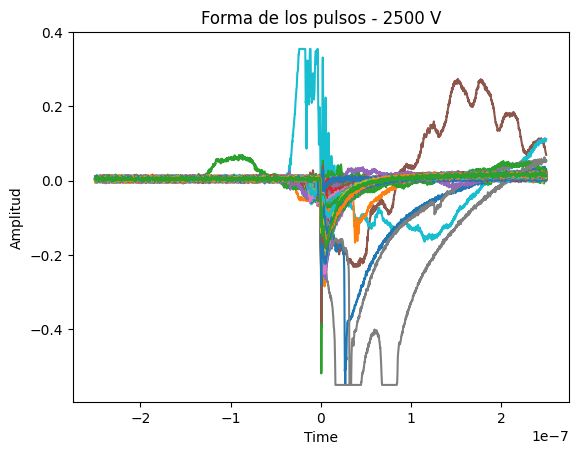

In [ ]:
# Para ver la forma de los pulsos
for archivo in archivos:
    Data = pd.read_csv(archivo, header=4)
    plt.plot(Data["Time"], Data["Ampl"])

plt.xlabel("Time")
plt.ylabel("Amplitud")
plt.title("Forma de los pulsos - 2500 V")
plt.show()


In [ ]:
# Aquí aplicamos el primer filtro, descartando aquellos con voltaje positivo.
archivosv = []
archivos_descartados = []

for archivo in archivos:
    Data = pd.read_csv(archivo, header=4)

    if (Data["Ampl"] > 0.05).any():
        archivos_descartados.append(archivo)
    else:
        archivosv.append(archivo)

print("Archivos revisados:", len(archivos))
print("Archivos descartados:", len(archivos_descartados))
print("Archivos válidos:", len(archivosv))

Archivos revisados: 833
Archivos descartados: 6
Archivos válidos: 827


In [ ]:
archivosv = []
archivos_descartados = []

for archivo in archivos:
    Data = pd.read_csv(archivo, header=4)

    # Filtro 1: descarta trazas que tengan algún voltaje positivo mayor a 0.04 V
    filtro1 = (Data["Ampl"] > 0.04).any()

    # Filtro 2: descarta trazas que presenten un pico positivo (> 0.02 V)
    # dentro de la ventana temporal entre 0.13e-7 s y 0.2e-7 s (13 ns a 20 ns)
    filtro2 = (
        (Data["Time"] > 0.13e-7) &
        (Data["Time"] < 0.2e-7) &
        (Data["Ampl"] > 0.02)
    ).any()

    # Filtro 3: descarta pulsos cuya amplitud mínima NO supere los -0.150 V hacia abajo
    # (es decir, pulsos demasiado pequeños o cercanos al ruido de línea base)
    filtro3 = ((np.min(Data["Ampl"])) > -0.150)

    # Si cumple cualquiera de las tres condiciones anteriores, se manda a descartados; de lo contrario, se guarda como pulso válido en el archivo.
    if filtro1 or filtro2 or filtro3:
        archivos_descartados.append(archivo)
    else:
        archivosv.append(archivo)

print("Archivos revisados:", len(archivos))
print("Archivos descartados:", len(archivos_descartados))
print("Archivos válidos:", len(archivosv))

Archivos revisados: 833
Archivos descartados: 548
Archivos válidos: 285


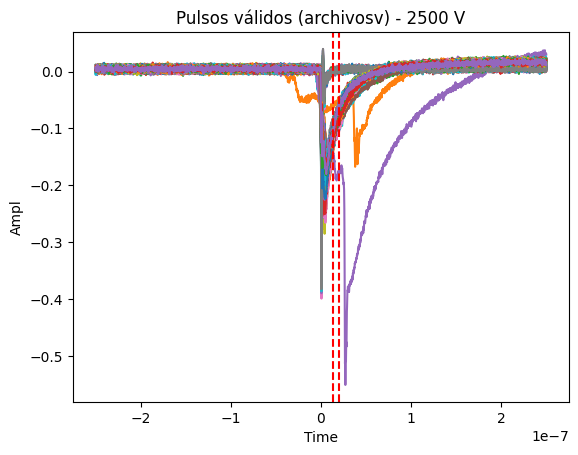

In [ ]:
# Graficamos el primer filtro (trazas válidas).
for archivo in archivosv:
    Data = pd.read_csv(archivo, header=4)
    plt.plot(Data["Time"], Data["Ampl"])

# Líneas de referencia opcionales para ubicar la ventana de tiempo de filtro2
plt.axvline(0.13e-7, color="red", linestyle="--")
plt.axvline(0.2e-7, color="red", linestyle="--")

plt.xlabel("Time")
plt.ylabel("Ampl")
plt.title("Pulsos válidos (archivosv) - 2500 V")
plt.show()

In [ ]:
# Ejemplo de cálculo de rate (ajustando los minutos_totales  al tiempo real de  toma de 2500 V)
num_pulsos = len(archivosv)
minutos_totales = 265
rate = num_pulsos / minutos_totales

print(f"Rate: {rate:.4f} eventos por minuto")

Rate: 1.0755 eventos por minuto


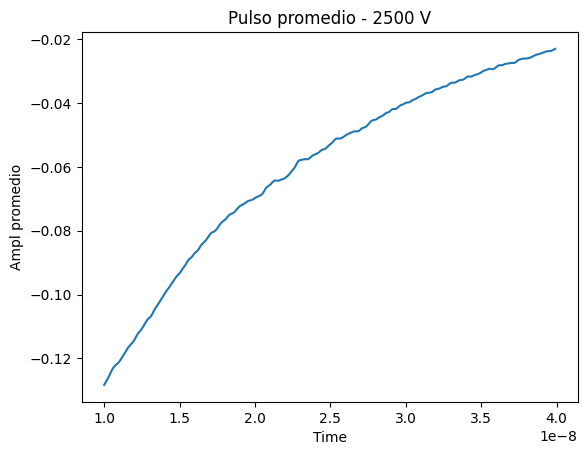

In [ ]:
# Hacer el promedio de todos los archivos válidos y recortar ventana de interés
amplitudes = []
tiempos = []

for archivo in archivosv:
    Data = pd.read_csv(archivo, header=4)
    # Recorta por ejemplo la región alrededor del pulso (ajusta el rango según tu eje Time)
    tramo = Data[(Data["Time"] >= 0.10e-7) & (Data["Time"] <= 0.40e-7)]
    amplitudes.append(tramo["Ampl"].values)
    tiempos.append(tramo["Time"].values)

# Este es el promedio punto a punto de amplitud y tiempo (asegurando igual longitud)
if len(amplitudes) > 0:
    min_len = min(len(a) for a in amplitudes)
    amp_prom = np.mean([a[:min_len] for a in amplitudes], axis=0)
    time_prom = tiempos[0][:min_len]

    plt.plot(time_prom, amp_prom)
    plt.xlabel("Time")
    plt.ylabel("Ampl promedio")
    plt.title("Pulso promedio - 2500 V")
    plt.show()

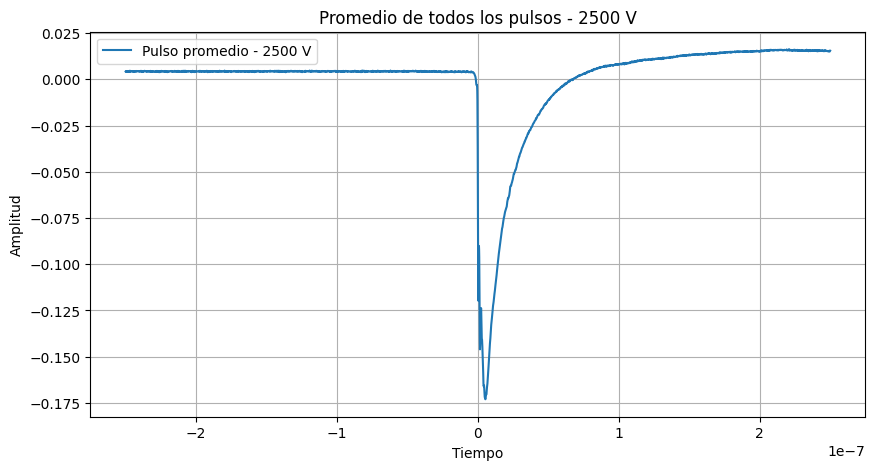

In [ ]:
amplitudes = []
tiempos = []
# Recorremos cada archivo CSV y guardamos los arreglos de amplitud y tiempo
# (Para promediar solo los pulsos filtrados, en vez del 'archivos' uso 'archivosv')
for archivo in archivosv:
    Data = pd.read_csv(archivo, header=4)
    amplitudes.append(Data["Ampl"].to_numpy())
    tiempos.append(Data["Time"].to_numpy())

# Convertimos la lista de trazas a un arreglo 2D de NumPy y calculamos el promedio a lo largo del eje 0 (promediando todos los pulsos en cada instante de tiempo)
amplitudes = np.array(amplitudes)
amplitud_promedio = np.mean(amplitudes, axis=0)

# Grafica del pulso promedio resultante
plt.figure(figsize=(10, 5))
plt.plot(tiempos[0], amplitud_promedio, label="Pulso promedio - 2500 V")
plt.xlabel("Tiempo")
plt.ylabel("Amplitud")
plt.title("Promedio de todos los pulsos - 2500 V")
plt.grid()
plt.legend()
plt.show()

In [ ]:
# Sellecciono los datos anteriores al tiempo 0.
ruido = tiempos[0] < 0

# Para las amplitudes correspondientes al ruido sobre el pulso promedio
amplitudes_ruido = amplitud_promedio[ruido]

ruido_maximo = np.max(amplitudes_ruido)
ruido_minimo = np.min(amplitudes_ruido)

print("Máximo del ruido:", ruido_maximo)
print("Mínimo del ruido:", ruido_minimo)

Máximo del ruido: 0.004741153275789473
Mínimo del ruido: -0.05991756456140353


In [ ]:
# Cantidad de pulsos limpios (válidos) y de ruido (descartados)
limpios = len(archivosv)
ruido_total = len(archivos_descartados)

# Proporción y porcentaje de pulsos limpios
Pulsos_clean = [limpios / len(archivos)]
print(f"Porcentaje de pulsos limpios: {Pulsos_clean[0] * 100:.2f}% ({limpios}/{len(archivos)})")

# Proporción y porcentaje de pulsos de ruido (complemento respecto a 1)
Pulsos_ruido = [1 - Pulsos_clean[0]]
print(f"Porcentaje de pulsos de ruido: {Pulsos_ruido[0] * 100:.2f}% ({ruido_total}/{len(archivos)})")

Porcentaje de pulsos limpios: 34.21% (285/833)
Porcentaje de pulsos de ruido: 65.79% (548/833)


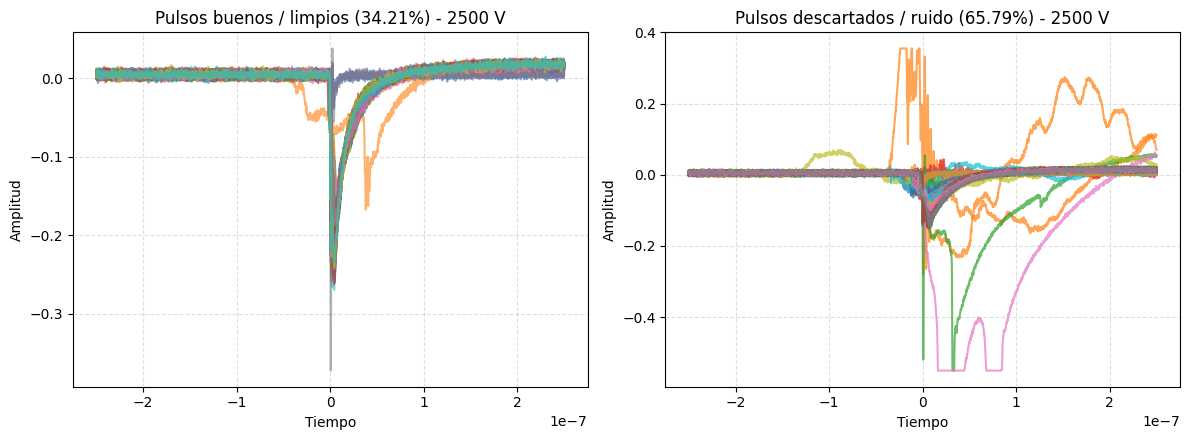

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for archivo in archivosv[:100]:
    Data = pd.read_csv(archivo, header=4)
    axes[0].plot(Data["Time"], Data["Ampl"], alpha=0.6)

axes[0].set_title(f"Pulsos buenos / limpios ({Pulsos_clean[0]*100:.2f}%) - 2500 V")
axes[0].set_xlabel("Tiempo")
axes[0].set_ylabel("Amplitud")
axes[0].grid(True, linestyle="--", alpha=0.4)

# Pulsos malos / descartados por ruido o anomalías
for archivo in archivos_descartados:
    Data = pd.read_csv(archivo, header=4)
    axes[1].plot(Data["Time"], Data["Ampl"], alpha=0.7)

axes[1].set_title(f"Pulsos descartados / ruido ({Pulsos_ruido[0]*100:.2f}%) - 2500 V")
axes[1].set_xlabel("Tiempo")
axes[1].set_ylabel("Amplitud")
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [ ]:

datos_actuales = np.asarray(datos)
print("Cantidad de datos:", len(datos_actuales))
print("Mínimo actual:", np.min(datos_actuales))
print("Máximo actual:", np.max(datos_actuales))

# 2. Inspeccionar el pulso promedio y dónde inicia realmente el pulso
plt.figure(figsize=(9, 4))
plt.plot(tiempos[0], amplitud_promedio, label="Pulso promedio - 2500 V")
plt.axvline(0, color="red", linestyle="--", label="t = 0")
plt.axhline(0, color="gray", linestyle=":", linewidth=1)
plt.xlabel("Tiempo")
plt.ylabel("Amplitud promedio")
plt.title("Inspección de línea base y disparo - 2500 V")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

# 3. Recorte seguro del ruido previo al pulso:
# Si notas que el pulso empieza a caer antes de t = 0, cambia t_corte (por ejemplo a -0.1e-7 o -0.2e-7)
t_corte = 0.0
mascara_ruido = tiempos[0] < t_corte
ruido_limpio = amplitud_promedio[mascara_ruido]

# Si hubiera algún punto aislado muy por debajo del piso de ruido (ej. < -0.015), revisa cuántos son:
outliers = ruido_limpio[ruido_limpio < -0.015]
print("Valores < -0.015 en la ventana de ruido:", len(outliers))

# Si quieres quitar esos valores atípicos extremos solo si es necesario, descomenta la siguiente línea:
# ruido_limpio = ruido_limpio[ruido_limpio >= -0.015]

datos = np.asarray(ruido_limpio)

# 4. Ajuste normal, R^2 y prueba de Shapiro-Wilk
media = np.mean(datos)
std = np.std(datos, ddof=1)

frecuencias, bordes = np.histogram(datos, bins=50, density=True)
centros = (bordes[:-1] + bordes[1:]) / 2
ajuste = norm.pdf(centros, media, std)

R2 = r2_score(frecuencias, ajuste)

# Shapiro-Wilk funciona mejor con muestras de hasta 5000 elementos
muestra_shapiro = datos if len(datos) <= 5000 else np.random.choice(datos, size=5000, replace=False)
estadistico, p_value = shapiro(muestra_shapiro)

# 5. Gráfica del histograma y curva normal
plt.figure(figsize=(8, 5))
plt.hist(datos, bins=50, density=True, alpha=0.6, label="Ruido limpio (2500 V)")

x = np.linspace(datos.min(), datos.max(), 500)
plt.plot(x, norm.pdf(x, media, std), linewidth=2, label="Ajuste Normal")

plt.xlabel("Amplitud")
plt.ylabel("Densidad")
plt.title("Ajuste normal del ruido - 2500 V")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

print(f"Media = {media:.8f}")
print(f"Desviación estándar = {std:.8f}")
print(f"R² = {R2:.6f}")
print(f"p-value = {p_value:.6e}")

NameError: name 'datos' is not defined

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, skew, kurtosis, shapiro
from sklearn.metrics import r2_score

# 1. Seleccionamos un solo pulso de la carpeta de 2500 V (cambia el índice 0 por el archivo que gustes)
# Puedes usar 'archivosv[0]' para tomar un pulso válido o 'archivos[0]' del total
pulso_muestra = pd.read_csv(archivosv[0], header=4)

# Extraemos el ruido de línea base previo al disparo (Time < 0) de ese único pulso
datos = pulso_muestra.loc[pulso_muestra["Time"] < 0, "Ampl"].dropna()

# 2. Estadísticos descriptivos y de forma
media = datos.mean()
std = datos.std()          # muestral (ddof=1)
varianza = std ** 2
asimetria = skew(datos)
curtosis = kurtosis(datos)

# 3. Histograma normalizado y ajuste normal en los centros de los bins
bins = 50
frecuencias, bordes = np.histogram(datos, bins=bins, density=True)
centros = (bordes[:-1] + bordes[1:]) / 2
ajuste = norm.pdf(centros, media, std)

R2 = r2_score(frecuencias, ajuste)
estadistico_sw, p_value = shapiro(datos)

# 4. Gráfica
plt.figure(figsize=(8, 5))
plt.hist(datos, bins=bins, density=True, alpha=0.6, label="Ruido de 1 pulso (2500 V)")

x = np.linspace(datos.min(), datos.max(), 500)
plt.plot(x, norm.pdf(x, media, std), linewidth=2, label="Ajuste Normal")

plt.xlabel("Amplitud")
plt.ylabel("Densidad")
plt.title("Análisis de ruido de un pulso - 2500 V")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

# 5. Resultados
print(f"Archivo analizado : {archivosv[0]}")
print(f"Muestras de ruido : {len(datos)}")
print(f"Media             : {media:.8f}")
print(f"Desviación est.   : {std:.8f}")
print(f"Varianza          : {varianza:.10e}")
print(f"Asimetría         : {asimetria:.6f}")
print(f"Curtosis          : {curtosis:.6f}")
print(f"R²                : {R2:.6f}")
print(f"Shapiro W         : {estadistico_sw:.6f} | p-value = {p_value:.6e}")
